
# RUSBoost Predictive Maintenance (Fair Comparison Framework)

This notebook implements the **fair-comparison setup** between:

- Random Forest (earlier paper)
- RUSBoost (follow-up paper)
- XGBoost (New Model Added for comparison)

It ensures:
- Same preprocessing
- Same feature space
- Same validation protocol
- Model-specific training only where appropriate

---

### Methodology Statement

To ensure fair comparison, the two frameworks were evaluated under the same data preprocessing, feature space, and validation protocol. However, model hyperparameters were selected in a model-specific manner, since Random Forest and RUSBoost rely on different learning mechanisms and therefore should not be constrained to identical training settings.


## Step 1 — Data Loading and Preparation

In [1]:
import sys
sys.path.append(".")

In [2]:
import os
print(os.getcwd())

/Users/martinwalterampah/Desktop/Final_Research_Project


In [3]:
import importlib
import Scripts.RUSBoostTrain

importlib.reload(Scripts.RUSBoostTrain)
from Scripts.RUSBoostTrain import train_rusboost

In [4]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from Scripts.RUSBoostTrain import train_rusboost
from Scripts.RUSBoostTrain import _to_serializable

%load_ext autoreload
%autoreload 2

CSV_PATH = "Data_file/ai4i2020.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
rus_raw, rus_calibrated, X_test, y_test, y_pred_rus, y_proba_rus, results = train_rusboost("configs/RUSBoost/RUStrain.yaml")
print(results.keys())

Chosen Threshold: 0.03474747474747475
Calibration Recall: 0.9706
Calibration Precision: 0.2651
Best deferral tau: 0.5000
Deferral cost/sample: 0.2055
Coverage at best tau: 0.9270
dict_keys(['model', 'step4_thresholding', 'step5_calibration', 'step6_conformal_calibration', 'step7_deferral_tuning', 'step9_final_evaluation', 'artifact_paths'])


In [16]:
# =========================================================
# Create timestamped experiment folder + save artifacts
# =========================================================

import yaml
import joblib
import os
import json
from datetime import datetime
from pathlib import Path
import pandas as pd

# --- 1. Create timestamp ---
timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# --- 2. Define experiment directory ---
base_dir = "experiments_rusboost"
run_dir = os.path.join(base_dir, f"run_{timestamp}")
os.makedirs(run_dir, exist_ok=True)

print(f"[RUSBoost] directory created: {run_dir}")
# ---------------------------------------------------------
# 3. Save models
# ---------------------------------------------------------
joblib.dump(rus_raw, os.path.join(run_dir, "rus_raw.pkl"))
joblib.dump(rus_calibrated, os.path.join(run_dir, "rusboost_calibrated.pkl"))

print("Models saved")

# ---------------------------------------------------------
# 4. Save config
# ---------------------------------------------------------
config_src = "configs/RUSBoost/RUStrain.yaml"
config_dst = os.path.join(run_dir, "RUStrain.yaml")

with open(config_src, "r") as f:
    config_data = yaml.safe_load(f)

with open(config_dst, "w") as f:
    yaml.dump(config_data, f)

print("Config saved")

# ---------------------------------------------------------
# 5. Save FULL pipeline results (ALL STEPS)
# ---------------------------------------------------------
results_path = os.path.join(run_dir, "full_pipeline_results.json")

with open(results_path, "w") as f:
    #json.dump(results, f, indent=4)
    json.dump(_to_serializable(results), f, indent=4)

print(f"Full pipeline results saved: {results_path}")

# ---------------------------------------------------------
# 6. Extract key results
# ---------------------------------------------------------
step4 = results["step4_thresholding"]
step5 = results["step5_calibration"]
step6 = results["step6_conformal_calibration"]
step7 = results["step7_deferral_tuning"]
step9 = results["step9_final_evaluation"]
artifacts = results["artifact_paths"]

# ---------------------------------------------------------
# 7. Save summary metrics (paper-ready)
# ---------------------------------------------------------
summary_metrics = {
    "model": "RUSBoost",

    # Step 4
    "threshold": step4["base_threshold"],

    # Step 5
    "brier_score": step5["brier_score"],
    "log_loss": step5["log_loss"],

    # Step 6
    "conformal_coverage_cal": step6["coverage_cal"],
    "conformal_avg_set_size_cal": step6["avg_set_size_cal"],

    # Step 7
    "best_tau": step7["best_tau"],
    "cost_per_sample": step7["best_cost_per_sample"],
    "coverage_after_deferral": step7["coverage_at_best_tau"],

    # Step 9 (FINAL RESULTS)
    "roc_auc": step9["overall_test"]["roc_auc"],
    "pr_auc": step9["overall_test"]["pr_auc"],

    "final_coverage": step9["selective_prediction_test"]["coverage"],
    "final_deferred_fraction": step9["selective_prediction_test"]["deferred_fraction"],
    "final_cost_per_sample": step9["selective_prediction_test"]["cost_per_sample"],
    "final_recall_retained": step9["selective_prediction_test"]["retained_recall"]
}

metrics_path = os.path.join(run_dir, "summary_metrics.json")

with open(metrics_path, "w") as f:
    #json.dump(summary_metrics, f, indent=4)
    json.dump(_to_serializable(summary_metrics), f, indent=4)

print("Summary metrics saved")

# ---------------------------------------------------------
# 8. Save Deferred-case summary (VERY IMPORTANT)
# ---------------------------------------------------------
deferred_summary = results["step9_final_evaluation"]["selective_prediction_test"]

deferred_path = os.path.join(run_dir, "deferred_case_summary.json")

with open(deferred_path, "w") as f:
    #json.dump(deferred_summary, f, indent=4)
    json.dump(_to_serializable(deferred_summary), f, indent=4)

print("Deferred-case summary saved")

# ---------------------------------------------------------
# 9. Save CSV artifacts from pipeline
# ---------------------------------------------------------
artifact_paths = results.get("artifact_paths", {})

if artifact_paths:
    for name, path in artifact_paths.items():
        if os.path.exists(path) and path.endswith(".csv"):
            df = pd.read_csv(path)
            df.to_csv(os.path.join(run_dir, f"{name}.csv"), index=False)

    print("Pipeline CSV artifacts copied into experiment folder")

# ---------------------------------------------------------
# 10. Notes file
# ---------------------------------------------------------
notes_path = os.path.join(run_dir, "notes.txt")

with open(notes_path, "w") as f:
    f.write(
        "Experiment Notes\n"
        "=================\n\n"
        f"Timestamp: {timestamp}\n\n"
        "Observations:\n- \n\n"
        "Key Results:\n"
        f"- ROC AUC: {summary_metrics['roc_auc']:.4f}\n"
        f"- PR AUC: {summary_metrics['pr_auc']:.4f}\n"
        f"- Cost per sample: {summary_metrics['final_cost_per_sample']:.4f}\n"
        f"- Deferred fraction: {summary_metrics['final_deferred_fraction']:.4f}\n\n"
        "Next Steps:\n- \n"
    )

print("Notes file created")

[RUSBoost] directory created: experiments_rusboost/run_2026-05-03_05-20-40
Models saved
Config saved
Full pipeline results saved: experiments_rusboost/run_2026-05-03_05-20-40/full_pipeline_results.json
Summary metrics saved
Deferred-case summary saved
Pipeline CSV artifacts copied into experiment folder
Notes file created


Results of Calibration/Certainty, Conformal on Calibration, Best deferral threshold, Final held-out Evaluation

In [6]:
from pprint import pprint

print("Available result keys:")
print(results.keys())

if "step4_thresholding" in results:
    print("\n=== Step 4: Threshold ===")
    pprint(results["step4_thresholding"])

print("=== Step 5: Calibration / certainty ===")
pprint(results["step5_calibration"])

print("\n=== Step 6: Conformal on calibration ===")
pprint(results["step6_conformal_calibration"])

print("\n=== Step 7: Best deferral threshold ===")
pprint(results["step7_deferral_tuning"])

print("\n=== Step 9: Final held-out evaluation ===")
pprint(results["step9_final_evaluation"])

print("\n=== artifacts_path ===")
pprint(results["artifact_paths"])

Available result keys:
dict_keys(['model', 'step4_thresholding', 'step5_calibration', 'step6_conformal_calibration', 'step7_deferral_tuning', 'step9_final_evaluation', 'artifact_paths'])

=== Step 4: Threshold ===
{'base_threshold': 0.03474747474747475, 'target_recall': 0.9}
=== Step 5: Calibration / certainty ===
{'brier_score': 0.017485673030248512,
 'certainty_max': 1.0,
 'certainty_mean': 0.9775000000000004,
 'certainty_median': 0.9994186046511628,
 'certainty_min': 0.6363636363636364,
 'log_loss': 0.058870701786256294}

=== Step 6: Conformal on calibration ===
{'alpha': 0.1,
 'ambiguous_rate_cal': 0.0,
 'avg_set_size_cal': 0.927,
 'coverage_cal': 0.9215,
 'empty_set_rate_cal': 0.073,
 'q_alpha': 0.10227272727272729,
 'q_level': 0.9005,
 'singleton_rate_cal': 0.927}

=== Step 7: Best deferral threshold ===
{'best_cost_per_sample': 0.2055,
 'best_tau': 0.5,
 'best_total_cost': 411.0,
 'coverage_at_best_tau': 0.927,
 'deferred_fraction_at_best_tau': 0.073,
 'retained_error_at_best_ta

Load saved CSV artifacts

In [7]:
import pandas as pd

artifact_paths = results.get("artifact_paths", {})

cal_df = pd.read_csv(artifact_paths["step5_step6_calibration_records"])
deferral_df = pd.read_csv(artifact_paths["step7_deferral_search"])
test_df = pd.read_csv(artifact_paths["step9_test_predictions"])

print("Calibration records shape:", cal_df.shape)
print("Deferral search shape:", deferral_df.shape)
print("Test predictions shape:", test_df.shape)

display(deferral_df.tail(20))
display(test_df.head(20))

Calibration records shape: (2000, 8)
Deferral search shape: (100, 11)
Test predictions shape: (2000, 12)


,tau,coverage,deferred_fraction,retained_error,retained_recall,retained_precision,fn,fp,deferred_count,total_cost,cost_per_sample
80,0.895960,0.9270,0.0730,0.043689,0.923077,0.23301,2,79,146,411.0,0.2055
81,0.900909,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
82,0.905859,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
83,0.910808,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
84,0.915758,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
85,0.920707,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
86,0.925657,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
87,0.930606,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
88,0.935556,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540
89,0.940505,0.8830,0.1170,0.001133,0.882353,1.00000,2,0,234,508.0,0.2540


,y_true,p0,p1,certainty,base_pred,final_pred_with_deferral,deferred,retained,cp_set,cp_set_size,cp_ambiguous,cp_covered
0,0,0.307692,0.692308,0.692308,1,-1,1,0,{},0,1,0
1,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
2,0,0.897727,0.102273,0.897727,1,1,0,1,{0},1,0,1
3,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
4,0,0.897727,0.102273,0.897727,1,1,0,1,{0},1,0,1
5,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
6,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
7,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
8,0,0.999419,0.000581,0.999419,0,0,0,1,{0},1,0,1
9,0,0.897727,0.102273,0.897727,1,1,0,1,{0},1,0,1


Visualize risk–coverage

<Figure size 800x600 with 0 Axes>

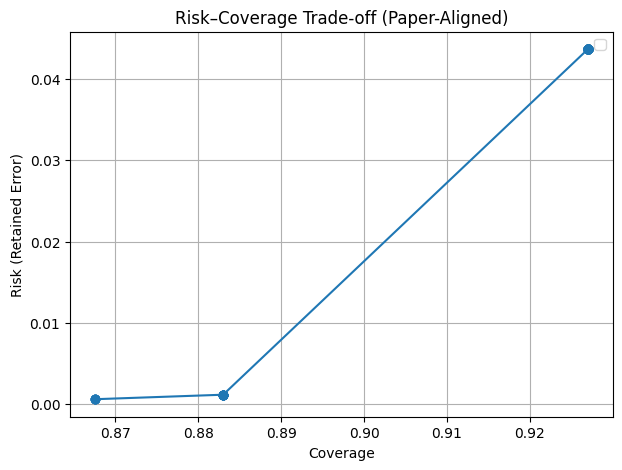

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))

plt.figure(figsize=(7, 5))
plt.plot(deferral_df["coverage"], deferral_df["retained_error"], marker="o")
plt.xlabel("Coverage")
plt.ylabel("Risk (Retained Error)")
plt.title("Risk–Coverage Trade-off (Paper-Aligned)")
plt.legend()
plt.grid(True)
plt.show()

Visualize Cost–coverage

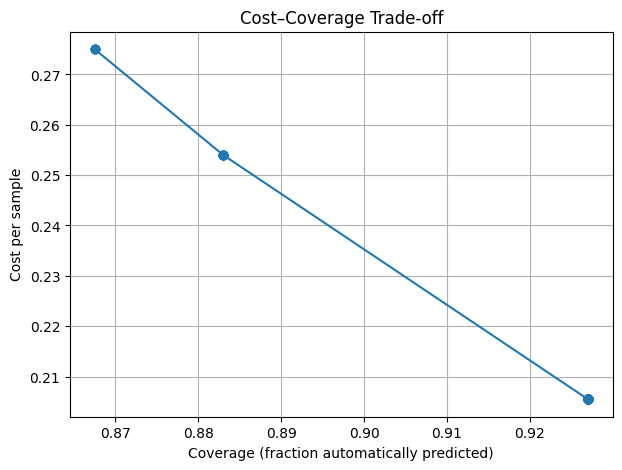

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.plot(deferral_df["coverage"], deferral_df["cost_per_sample"], marker="o")
plt.xlabel("Coverage (fraction automatically predicted)")
plt.ylabel("Cost per sample")
plt.title("Cost–Coverage Trade-off")
plt.grid(True)
plt.show()

Deferred-case summary

In [10]:
deferred_rate = results["step9_final_evaluation"]["selective_prediction_test"]["deferred_fraction"]
coverage = results["step9_final_evaluation"]["selective_prediction_test"]["coverage"]
cost_per_sample = results["step9_final_evaluation"]["selective_prediction_test"]["cost_per_sample"]

print(f"Deferred fraction: {deferred_rate:.4f}")
print(f"Coverage: {coverage:.4f}")
print(f"Cost per sample: {cost_per_sample:.4f}")

Deferred fraction: 0.0590
Coverage: 0.9410
Cost per sample: 0.2105


In [21]:
# =========================================================
# Step 5–9: Full Pipeline Evaluation Export
# =========================================================

import json
import pandas as pd
import os

# --- 1. Extract structured results ---
step4 = results.get("step4_thresholding",{})
step5 = results.get("step5_calibration", {})
step6 = results.get("step6_conformal_calibration", {})
step7 = results.get("step7_deferral_tuning", {})
step9 = results.get("step9_final_evaluation", {})
artifacts = results.get("artifact_paths", {})

# --- 2. Deferred-case summary (core research output) ---
selective = step9.get("selective_prediction_test", {})

deferred_summary = {
    "coverage": selective.get("coverage"),
    "deferred_fraction": selective.get("deferred_fraction"),
    "deferred_count": selective.get("deferred_count"),
    "retained_error": selective.get("retained_error"),
    "retained_recall": selective.get("retained_recall"),
    "retained_precision": selective.get("retained_precision"),
    "cost_per_sample": selective.get("cost_per_sample"),
    "total_cost": selective.get("total_cost"),
}

# --- 3. Combine all pipeline results ---
full_pipeline_results = {
    "model": "RUSBoost",
    "step4_thresholding": step4,
    "step5_calibration": step5,
    "step6_conformal": step6,
    "step7_deferral": step7,
    "step9_final": step9,
    "artifacts": artifacts,

    "deferred_case_summary": deferred_summary
}

# --- 4. Save JSON summary ---
full_results_path = os.path.join(run_dir, "full_pipeline_results.json")

with open(full_results_path, "w") as f:
    json.dump(_to_serializable(full_pipeline_results), f, indent=4)

print(f"Full pipeline results saved to: {full_results_path}")

Full pipeline results saved to: experiments_rusboost/run_2026-05-03_05-20-40/full_pipeline_results.json


In [21]:
selected_uids = {
    "TWF": [2672, 3866, 6341, 8358, 9019],
    "HDF": [3237, 4079, 4174, 4327, 4502],
    "PWF": [464, 1493, 3001, 7537, 8583],
    "OSF": [250, 3020, 5400, 7592, 9660],
}

all_selected_uids = [uid for group in selected_uids.values() for uid in group]

selected_cases = df[df["UDI"].isin(all_selected_uids)].copy().sort_values("UDI")

selected_cases[["UDI", "Type", "Machine failure", "TWF", "HDF", "PWF", "OSF"]]


KeyError: 'UDI'